In [1]:
%pylab inline
import os
import gc
import matplotlib
import numpy as np
import astropy.io.fits as pyfits
import astropy.table as astTab
from configparser import ConfigParser
from pixel3D import cartesianGrid3D
from astropy.wcs import WCS
from scipy.stats import norm as statnorm
import matplotlib as mpl
import catutil as utilities

Populating the interactive namespace from numpy and matplotlib


In [9]:
def mapPlot(pname,label,norm,raPList=None,decPList=None,cmap='viridis',gcolor='white',interpolate=None):
    fs=20
    assert (raPList is None)==(decPList is None)
    pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
    lenList={}
    imgList={}
    wcsList={}
    cmax=0.
    for fieldname in pltList:
        data=pyfits.getdata(os.path.join(outDir,'%s_%sMap.fits' %(fieldname,pname)))
        header=pyfits.getheader(os.path.join(outDir,'%s_%sMap.fits' %(fieldname,pname)))
        wcsList.update({fieldname:WCS(header)})
        print(fieldname)
        print(data.shape)
        lenList.update({fieldname:data.shape})
        imgList.update({fieldname:data})
        fmax=np.max(data)
        if fmax>cmax:
            cmax=fmax

    configName  =   'wrkDir/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/char.ini'
    parser2      =   ConfigParser()
    parser2.read(configName)
    plt.close()

    fig = plt.figure(figsize=(15,10))
    ratio=int(1./(lenList['VVDS'][-1]/lenList['VVDS'][-2]/lenList['XMM'][-1]*lenList['XMM'][-2]+1.)*10.+0.5)
    ax1 = plt.subplot2grid((8, 11), (0, 0), colspan=ratio,rowspan=2,projection=wcsList['XMM'],aspect='equal')
    ax1.set_title('XMM',fontsize=fs)
    ax1.imshow(imgList['XMM'],origin='lower',norm=norm,cmap=cmap,interpolation=interpolate)
    ax1.grid(color=gcolor, ls='dotted')
    ax1.coords[0].set_major_formatter('d.d')
    ax1.set_ylabel('dec [deg]',fontsize=fs)

    ax2 = plt.subplot2grid((8, 11), (0, ratio+1), colspan=10-ratio,rowspan=2,projection=wcsList['VVDS'],aspect='equal')
    ax2.set_title('VVDS',fontsize=fs)
    ax2.imshow(imgList['VVDS'],origin='lower',norm=norm,cmap=cmap,interpolation=interpolate)
    ax2.grid(color=gcolor, ls='dotted')
    ax2.coords[0].set_major_formatter('d.d')

    ratio=int(1./(lenList['GAMA15H'][-1]/lenList['GAMA15H'][-2]/lenList['GAMA09H'][-1]*lenList['GAMA09H'][-2]+1.)*10.+0.5)
    ax3 = plt.subplot2grid((8, 11), (2, 0), colspan=ratio,rowspan=2,projection=wcsList['GAMA09H'])
    ax3.set_title('GAMA09H',fontsize=fs)
    ax3.imshow(imgList['GAMA09H'],origin='lower',norm=norm,cmap=cmap,interpolation=interpolate)
    ax3.grid(color=gcolor, ls='dotted')
    ax3.coords[0].set_major_formatter('d.d')
    ax3.set_ylabel('dec [deg]',fontsize=fs)

    ax4 = plt.subplot2grid((8, 11), (2, ratio+1), colspan=10-ratio,rowspan=2,projection=wcsList['GAMA15H'])
    ax4.set_title('GAMA15H',fontsize=fs)
    ax4.imshow(imgList['GAMA15H'],origin='lower',norm=norm,cmap=cmap,interpolation=interpolate)
    ax4.grid(color=gcolor, ls='dotted')
    ax4.coords[0].set_major_formatter('d.d')

    ax5 = plt.subplot2grid((8, 11), (4, 0), colspan=10,rowspan=2,projection=wcsList['WIDE12H'])
    ax5.set_title('WIDE12H',fontsize=fs)
    ax5.imshow(imgList['WIDE12H'],origin='lower',norm=norm,cmap=cmap,interpolation=interpolate)
    ax5.grid(color=gcolor, ls='dotted')
    ax5.coords[0].set_major_formatter('d.d')
    ax5.set_ylabel('dec [deg]',fontsize=fs)

    ax6 = plt.subplot2grid((8, 11), (6, 0), colspan=9,rowspan=2,projection=wcsList['HECTOMAP'])
    ax6.set_title('HECTOMAP',fontsize=fs)
    mm=ax6.imshow(imgList['HECTOMAP'],origin='lower',norm=norm,cmap=cmap,interpolation=interpolate)
    ax6.grid(color=gcolor, ls='dotted')
    ax6.coords[0].set_major_formatter('d.d')
    ax6.set_xlabel('ra [deg]',fontsize=fs)
    ax6.set_ylabel('dec [deg]',fontsize=fs)
    #plt.tight_layout()
    plt.subplots_adjust(bottom=0.05, right=0.92, top=0.95)
    cax = plt.axes([0.95, 0.05, 0.01, 0.9])
    plt.colorbar(mm,aspect=10,cax=cax)
    cax.set_ylabel(label,fontsize=fs)
    cp='#ff0000'
    if raPList is not None:
        ax1.scatter(raPList['XMM'],decPList['XMM'],s=.65,c=cp)
        ax2.scatter(raPList['VVDS'],decPList['VVDS'],s=.65,c=cp)
        ax3.scatter(raPList['GAMA09H'],decPList['GAMA09H'],s=.65,c=cp)
        ax4.scatter(raPList['GAMA15H'],decPList['GAMA15H'],s=.65,c=cp)
        ax5.scatter(raPList['WIDE12H'],decPList['WIDE12H'],s=.65,c=cp)
        ax6.scatter(raPList['HECTOMAP'],decPList['HECTOMAP'],s=.65,c=cp)
    fig.savefig(os.path.join(outDir,'%sMap.eps'%pname))
    fig.savefig(os.path.join(outDir,'%sMap.png'%pname))
    return

In [3]:
if False:
    workDir='/home/xiangchong/work/gw_ipmu/work/'
else:
    workDir='/work/xiangchong.li/work/'
configName  =   os.path.join(workDir,'galSim-HSC/s19/s19-1/config-nl1-test.ini')
parser      =   ConfigParser()
parser.read(configName)
outDir      =   os.path.join(workDir,'galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/plot/densityMap/')
inDir       =   os.path.join(workDir,'massMapSparse/s19/reGaus_catalog/')
inDir2      =   os.path.join(workDir,'galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_obs_reGaus_no_m/')
inDir3      =   os.path.join(workDir,'galSim-HSC/s19/s19-1/anaCat_newS19Mask_fdeltacut/catalog_others/')

In [12]:
psfs=astTab.Table.read('wrkDir/s19/s19-1/info_newS19Mask_fd001_sim.csv')
raPList={}
decPList={}
gridInfo    =   cartesianGrid3D(parser)
# PSF map
for fieldname in utilities.field_names:
    _ofname=os.path.join(outDir,'%s_fwhmMap.fits' %fieldname)
    if not os.path.isfile(_ofname):
        infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
        data=pyfits.getdata(infname)
        ra,dec=utilities.get_radec(data)
        print(np.min(ra),np.max(ra))
        if fieldname=='VVDS':
            addR=(ra<300.).astype(int)*360
            ra+=addR
            addR=(raP<300.).astype(int)*360
            raP+=addR
        v=utilities.get_psf_size(data)
        z=data['dnnz_photoz_best']

        x,y=gridInfo.setupTanPlane(ra,dec)
        print(np.min(x),np.max(x))
        out=gridInfo.pixelize_data(x,y,z,v,ws=None)
        wcs_input_dict = {
            'CTYPE1': 'RA---TAN',
            'CUNIT1': 'deg',
            'CDELT1': 1./60.,
            'CRPIX1': gridInfo.nx//2+1,
            'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
            'NAXIS1': gridInfo.nx,
            'CTYPE2': 'DEC--TAN',
            'CUNIT2': 'deg',
            'CDELT2': 1./60.,
            'CRPIX2': gridInfo.ny//2+1, #fits 1 based
            'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
            'NAXIS2': gridInfo.ny
        }
        wcs_header = WCS(wcs_input_dict).to_header()
        pyfits.writeto(_ofname,out[0],header=wcs_header,overwrite=True)
        del data
        gc.collect()
    else:
        header=pyfits.getheader(_ofname)
        gridInfo.setupTanPlane(header=header)
    msk=psfs['field']==fieldname
    raP=psfs[msk]['psf_ra']
    decP=psfs[msk]['psf_dec']
    xP,yP=gridInfo.project_tan(raP,decP,pix=True)
    print(xP.max(),xP.min())
    print(yP.max(),yP.min())
    raPList.update({fieldname:(xP)})
    decPList.update({fieldname:(yP)})

621.9146232387598 10.930183682804255
304.53228451532385 17.720505218286
1500.4928705929947 24.664017951514836
403.9857830633073 8.38785674891981
2887.028831530319 44.306313593463074
384.72231005948714 10.962176185836006
1172.2207011435285 32.67911572762273
186.04729115552098 14.275817671804498
2024.753246157693 12.691794708966881
414.9620624019617 21.459545733931726
1654.4937237626937 7.045060480609777
225.5950320248222 10.675983751173419


XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


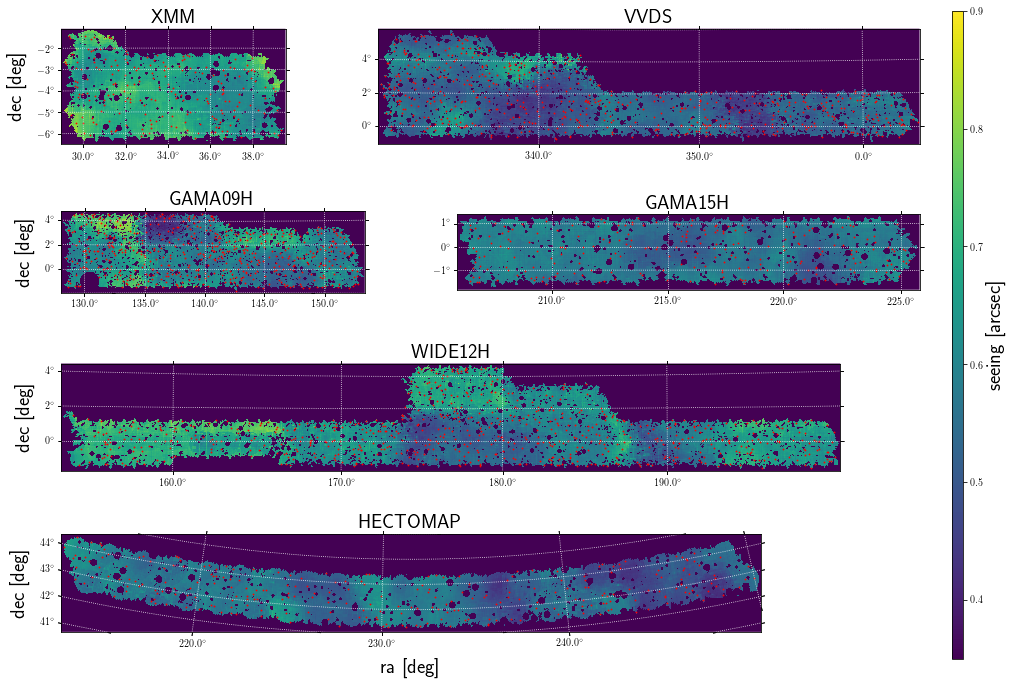

In [13]:
plt.close()
norm=mpl.colors.Normalize(vmin=0.35, vmax=0.90)
mapPlot('fwhm','seeing [arcsec]',norm,raPList=raPList,decPList=decPList,cmap='viridis')

In [8]:
# Input map
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir2,'%s_no_m.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
    v=data['i_inputcount_value']
    z=data['dnnz_photoz_best']
    
    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()
    
    pyfits.writeto(os.path.join(outDir,'%s_icountInMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del data
    gc.collect()

29.08622044291697 39.420959268049174
29.093784804406443 39.41687484206933
128.01455102845426 153.34985224249746
128.1980673366667 153.1421325965732
152.65993793963236 200.89527299207126
153.9430872013283 199.59751411485658
206.0090058801017 225.79877549093496
206.10603477658103 225.70206609813968
330.02490540182635 363.67665495614153
330.46954174206724 363.20539481020353
217.75405313497694 245.41064367210979
212.5738517005094 250.20554438882596


XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


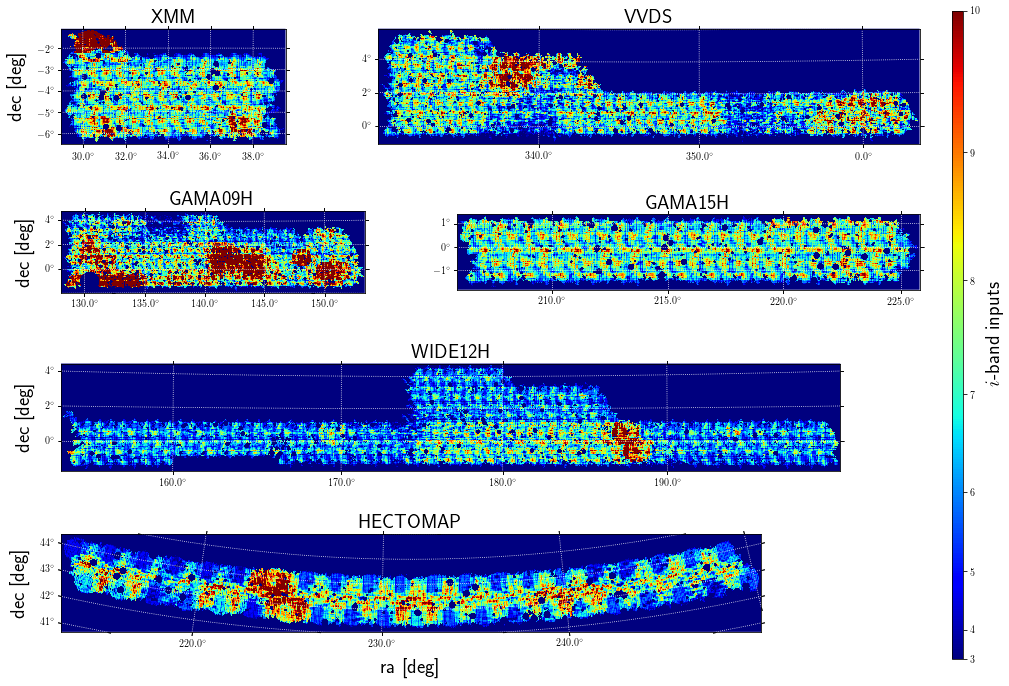

In [10]:
plt.close()
norm=mpl.colors.PowerNorm(vmin=3,vmax=10,gamma=1.6)
mapPlot('icountIn',r'$i$-band inputs',norm,cmap='jet')

#norm=mpl.colors.SymLogNorm(vmin=3, vmax=9,linthresh=1.)
#mapPlot('icountIn',r'$i$-band inputs',norm)

In [10]:
# Number map
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
        
    z=data['dnn_zbest']
    ra=data['ra']
    dec=data['dec']

    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v=None,ws=None)
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()
    pyfits.writeto(os.path.join(outDir,'%s_numMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out

    infname=os.path.join(inDir3,'%s_rand.fits'%fieldname )
    data=pyfits.getdata(infname)
    ra,dec=utilities.get_radec(data)
    if fieldname=='VVDS':
        addR=(ra<300.).astype(int)*360
        ra+=addR
    z=None
    v=None

    x,y=gridInfo.project_tan(ra,dec)
    out=gridInfo.pixelize_data(x,y,z,v,ws=None)/100.
    pyfits.writeto(os.path.join(outDir,'%s_areaMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out
    gc.collect()

29.08622044291697 39.420959268049174
29.093784804406443 39.41687484206933
128.01455102845426 153.34985224249746
128.1980673366667 153.1421325965732
152.65993793963236 200.89527299207126
153.9430872013283 199.59751411485658
206.0090058801017 225.79877549093496
206.10603477658103 225.70206609813968
330.02490540182635 363.67665495614153
330.46954174206724 363.20539481020353
217.75405313497694 245.41064367210979
212.5738517005094 250.20554438882596


XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


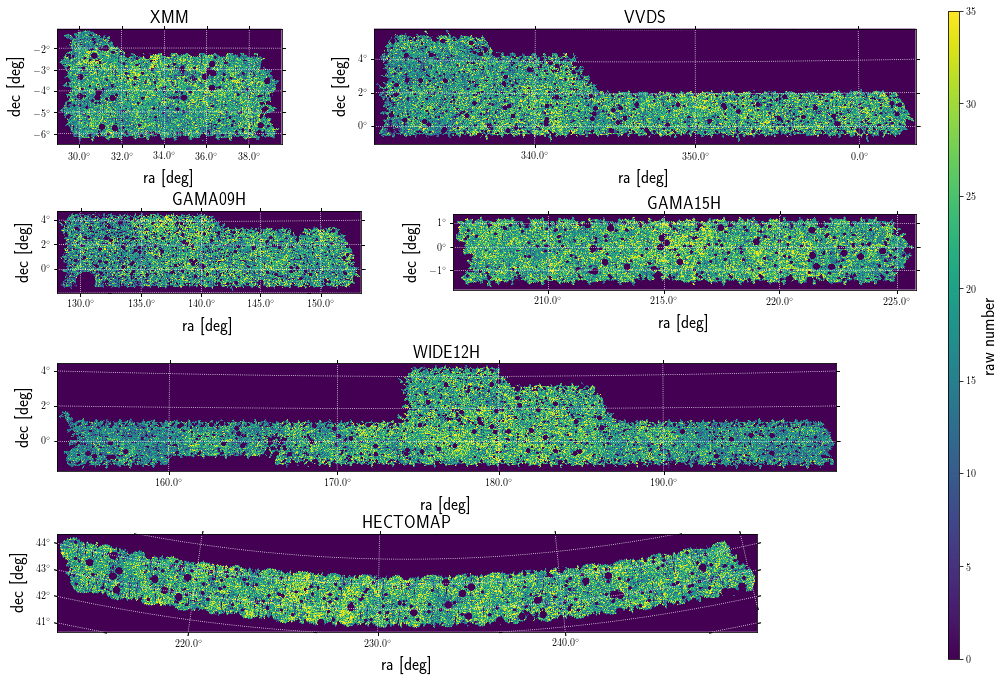

In [60]:
plt.close()
norm=mpl.colors.Normalize(vmin=0, vmax=35)
mapPlot('num','raw number',norm)

In [24]:
# Number map
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir,'%s.fits'%fieldname )
    data=pyfits.getdata(infname)
    if fieldname=='VVDS':
        addR=(data['ra']<300.).astype(int)*360
        data['ra']+=addR
    
    z=data['dnn_zbest']
    ra=data['ra']
    dec=data['dec']

    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v=None,ws=0.4**2.*data['weight'])
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()

    pyfits.writeto(os.path.join(outDir,'%s_wsMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out
    gc.collect()

29.086219696823967 39.420945858983316
29.093784804406443 39.41687484206933
128.0148302910242 153.3502141678189
128.1980673366667 153.1421325965732
152.66156939029062 200.89746604565678
153.9430872013283 199.59751411485658
206.0090069252839 225.7987689977325
206.10603477658103 225.70206609813968
330.0260677408365 363.6771613506724
330.46954174206724 363.20539481020353
217.69792926177686 245.36484428934793
212.5738517005094 250.20554438882596


XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


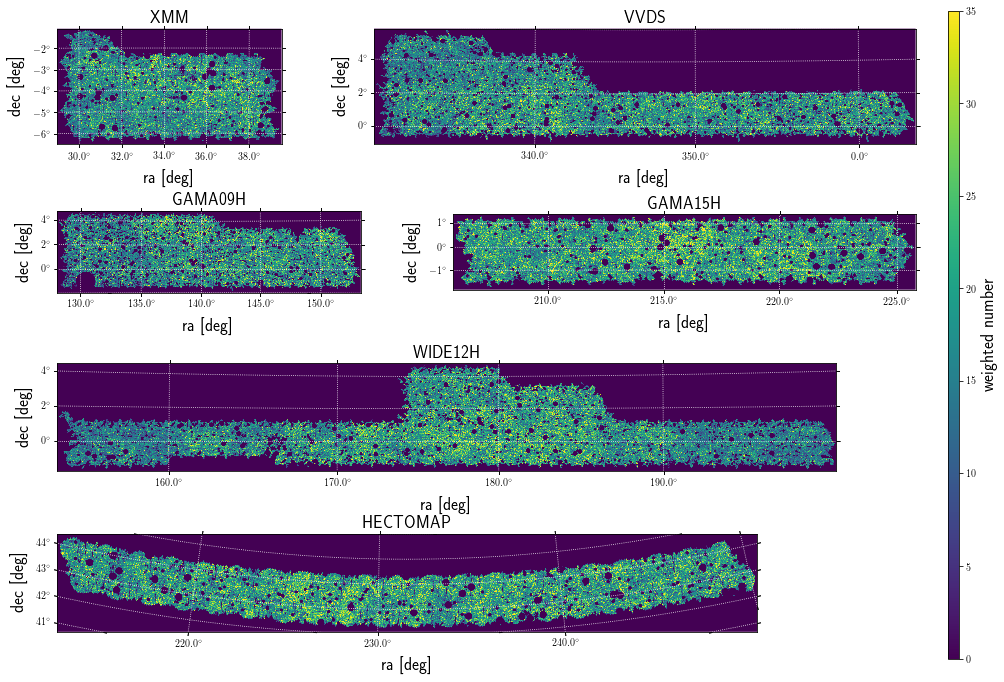

In [61]:
norm=mpl.colors.Normalize(vmin=0, vmax=35)
mapPlot('ws','weighted number',norm)

XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


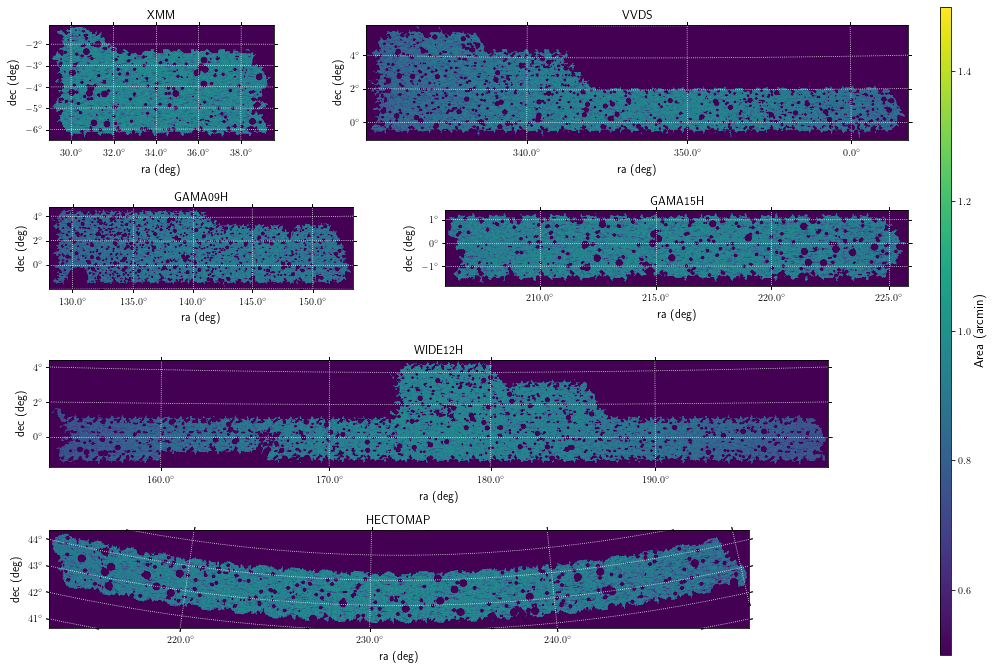

In [19]:
norm=mpl.colors.Normalize(vmin=0.5, vmax=1.5)
mapPlot('area','Area (arcmin)',norm)

In [30]:
for fieldname in mutilities.field_names:
    map1=pyfits.getdata(os.path.join(outDir,'%s_numMap.fits' %fieldname))
    map2=pyfits.getdata(os.path.join(outDir,'%s_wsMap.fits' %fieldname))
    mapA=pyfits.getdata(os.path.join(outDir,'%s_areaMap.fits' %fieldname))
    wcs_header=pyfits.getheader(os.path.join(outDir,'%s_numMap.fits' %fieldname))
    msk=(mapA>0)
    mapp1=np.zeros(map1.shape)
    mapp2=np.zeros(map1.shape)
    mapp1[msk]=map1[msk]/mapA[msk]
    mapp2[msk]=map2[msk]/mapA[msk]
    print(np.average(mapp1[msk]),np.average(mapp2[msk]))
    pyfits.writeto(os.path.join(outDir,'%s_nDensMap.fits' %fieldname),map1,header=wcs_header,overwrite=True)
    pyfits.writeto(os.path.join(outDir,'%s_wDensMap.fits' %fieldname),map2,header=wcs_header,overwrite=True)

21.952611485984683 19.1004353680351
22.59532511479435 20.181680925667756
23.152600799524 20.70198842054855
24.223548217786565 21.876292744386294
23.352825085661298 20.30806380451982
24.15023151395952 21.68515532761097


XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


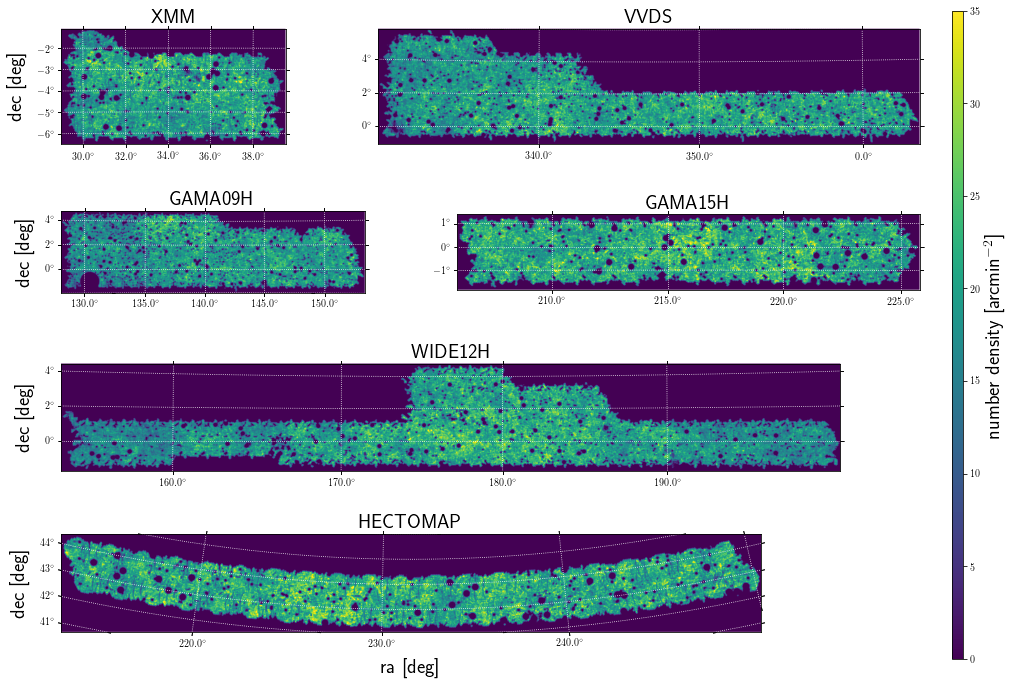

In [14]:
norm=mpl.colors.Normalize(vmin=0, vmax=35)
mapPlot('nDens','number density [arcmin$^{-2}$]',norm,cmap='viridis',interpolate='gaussian')

In [ ]:
norm=mpl.colors.Normalize(vmin=0, vmax=35)
mapPlot('wDens','effective number density [arcmin$^{-2}$]',norm,interpolate='gaussian')

XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


In [58]:
# Hex keys for the color scheme for shear catalog paper
plot_colors = {
    'GAMA09H' : '#d73027',
    'GAMA15H' : '#fc8d59',
    'HECTOMAP': '#fee090',
    'VVDS'    : '#000000',
    'WIDE12H' : '#91bfdb',
    'XMM'     : '#4575b4'
    }

pltList=['XMM','VVDS','GAMA09H','GAMA15H','WIDE12H','HECTOMAP']
xList={}
yList={}
cmax=0.
for fieldname in pltList:
    c=plot_colors[fieldname]
    datax=pyfits.getdata(os.path.join(outDir,'%s_fwhmMap.fits' %fieldname))
    datay=pyfits.getdata(os.path.join(outDir,'%s_wDensMap.fits' %fieldname))
    mask=datay>2.
    datax=datax[mask]
    datay=datay[mask]
    ind=np.arange(len(datay))
    np.random.shuffle(ind)
    print(fieldname,np.average(datay))
    xList.update({fieldname:datax[ind]})
    yList.update({fieldname:datay[ind]})

XMM 17.378594204274727
VVDS 17.337324096022837
GAMA09H 17.246217952314325
GAMA15H 19.281535082591404
WIDE12H 17.590747942368534
HECTOMAP 19.038257241472927


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


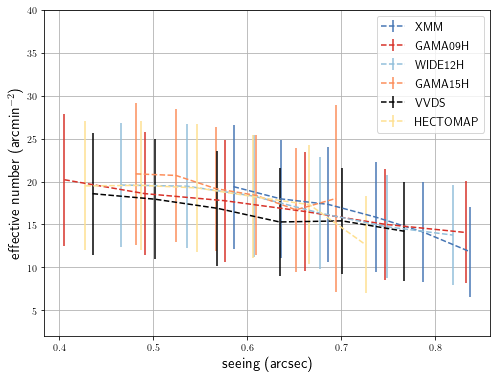

In [74]:
plt.close()
fig=plt.figure(figsize=(8,6))
ax=fig.add_subplot(1,1,1)
for fieldname in utilities.field_names:
    #ax.scatter(xList[fieldname][0::20],yList[fieldname][0::20],s=0.05,c=plot_colors[fieldname])
    up,xx=np.histogram(xList[fieldname],bins=6,weights=yList[fieldname])
    down=np.histogram(xList[fieldname],bins=6)[0]
    up2=np.histogram(xList[fieldname],bins=6,weights=yList[fieldname]**2.)[0]
    ave=up/down
    x2=up2/down
    std=np.sqrt(x2-ave**2.)
    xx=(xx[1:]+xx[:-1])/2.
    ax.errorbar(xx,ave,std,ls='--',c=plot_colors[fieldname],label=fieldname)
ax.set_ylim(2.,40.)
ax.set_xlabel('seeing (arcsec)',fontsize=15)
ax.set_ylabel('effective number (arcmin$^{-2}$)',fontsize=15)
plt.legend(loc='upper right',fontsize=12)
plt.grid()
fig.savefig(os.path.join(outDir,'ws-seeing.png'))
fig.savefig(os.path.join(outDir,'ws-seeing.eps'))

In [15]:
# colorterm map
for fieldname in mutilities.field_names:
    infname=os.path.join(inDir3,'%s_colorterm.fits'%fieldname )
    data=pyfits.getdata(infname)
    data0=pyfits.getdata(os.path.join(inDir2,'%s_no_m.fits'%fieldname ))
    assert np.all(data0['object_id']==data['object_id'])
    if fieldname=='VVDS':
        addR=(data0['i_ra']<300.).astype(int)*360
        data0['i_ra']+=addR
    
    mask=np.abs(data['i_filterfraction_unweighted']-0.5)<0.49
    v=data['i_offset']
    v[~mask]=0.
    z=np.ones(len(data))
    ra=data0['i_ra']
    dec=data0['i_dec']

    gridInfo    =   cartesianGrid3D(parser)
    x,y=gridInfo.setupTanPlane(ra,dec)
    print(np.min(x),np.max(x))
    print(np.min(ra),np.max(ra))
    out=gridInfo.pixelize_data(x,y,z,v=v,ws=None)
    wcs_input_dict = {
        'CTYPE1': 'RA---TAN',
        'CUNIT1': 'deg',
        'CDELT1': 1./60.,
        'CRPIX1': gridInfo.nx//2+1,
        'CRVAL1': gridInfo.xcgrid[gridInfo.nx//2],
        'NAXIS1': gridInfo.nx,
        'CTYPE2': 'DEC--TAN',
        'CUNIT2': 'deg',
        'CDELT2': 1./60.,
        'CRPIX2': gridInfo.ny//2+1, #fits 1 based
        'CRVAL2': gridInfo.ycgrid[gridInfo.ny//2],
        'NAXIS2': gridInfo.ny
    }
    wcs_header = WCS(wcs_input_dict).to_header()

    pyfits.writeto(os.path.join(outDir,'%s_imagDifMap.fits' %fieldname),out[0],header=wcs_header,overwrite=True)
    del out
    gc.collect()

29.08622044291697 39.420959268049174
29.093784804406443 39.41687484206933
128.01455102845426 153.34985224249746
128.1980673366667 153.1421325965732
152.65993793963236 200.89527299207126
153.9430872013283 199.59751411485658
206.0090058801017 225.79877549093496
206.10603477658103 225.70206609813968
330.02490540182635 363.67665495614153
330.46954174206724 363.20539481020353
217.75405313497694 245.41064367210979
212.5738517005094 250.20554438882596


XMM
(326, 634)
VVDS
(434, 2032)
GAMA09H
(414, 1534)
GAMA15H
(196, 1200)
WIDE12H
(402, 2908)
HECTOMAP
(234, 1672)


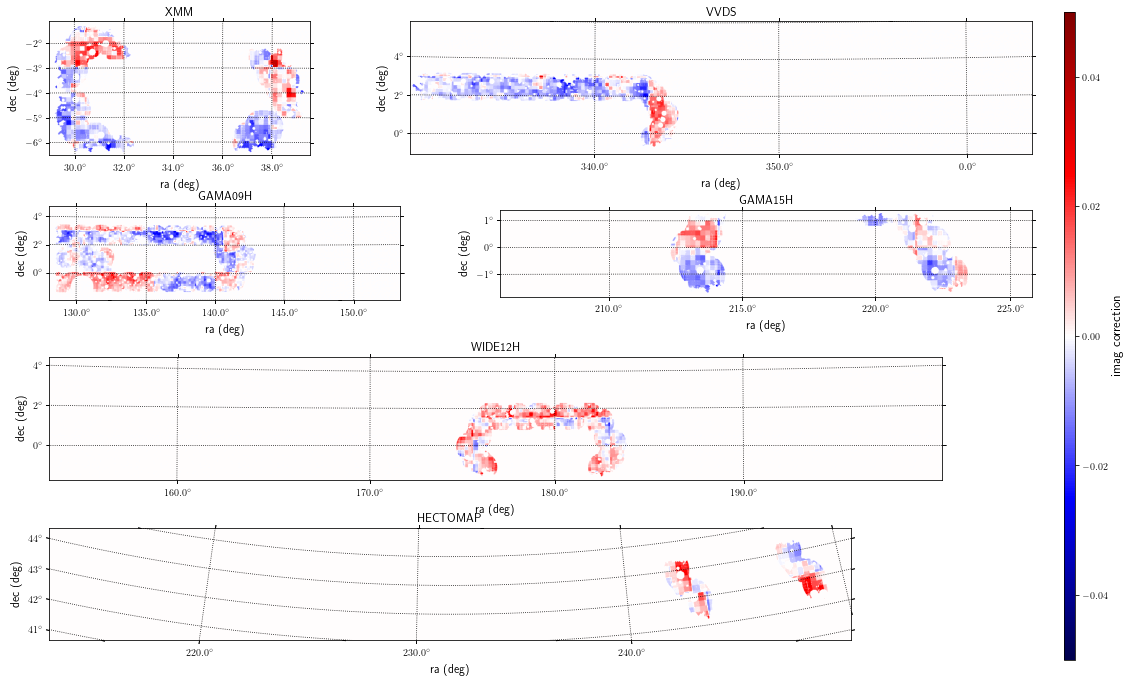

In [27]:
norm=mpl.colors.Normalize(vmin=-0.05, vmax=0.05)
mapPlot('imagDif','imag correction',norm,cmap='seismic',gcolor='black')

In [22]:
for fieldname in mutilities.field_names:
    print(np.abs(pyfits.getdata(os.path.join(outDir,'%s_colorDifMap.fits' %fieldname))).max())

0.03759000077843666
0.03313000127673149
0.035909999161958694
0.028289999812841415
0.033969998359680176
0.02996000088751316
